In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

Con $k = -b_n / r_e ^{1/n}$ y $1/n = p$:
\begin{align*}
    I(r)    &= I_0 e^{kr^p - 1} \\[7pt]
    I'(r)   &= (I_0 k p) r^{p-1} e^{kr^p - 1} \\[7pt]
    I''(r)  &= (I_0 k p) \left[ (p-1)r^{p-2} + kp r^{2(p-1)} \right] e^{kr^p - 1} \\[7pt]
    I'''(r) &= (I_0 k p) \left\{ \left[(p-1)(p-2)r^{p-3} + 2kp(p-1)r^{2p-3}\right] + kp r^{p-1}\left[(p-1)r^{p-2} + kpr^{2(p-1)}\right]\right\} e^{kr^p - 1}
\end{align*}

Como se busca minimizar $I'(r)$ y no $I(r)$, es necesario también tener $I'''(r)$. Para simplificar las expresiones, definimos:
\begin{align*}
    E(r) &:= e^{kr^p - 1} \\[7pt]
    F(r) &:= (p - 1)r^{p - 2} + kpr^{2p - 2} \\[7pt]
    G(r) &:= (p - 1)(p - 1)r^{p - 3} + kp(2p - 2)r^{2p - 3}
\end{align*}

La raíz encontrada r* = 8.4916708069 kpc para n = 0.5 cuenta con un error relativo porcentual de 2.9317e-08% respecto al valor exacto de 8.4916708094 kpc.


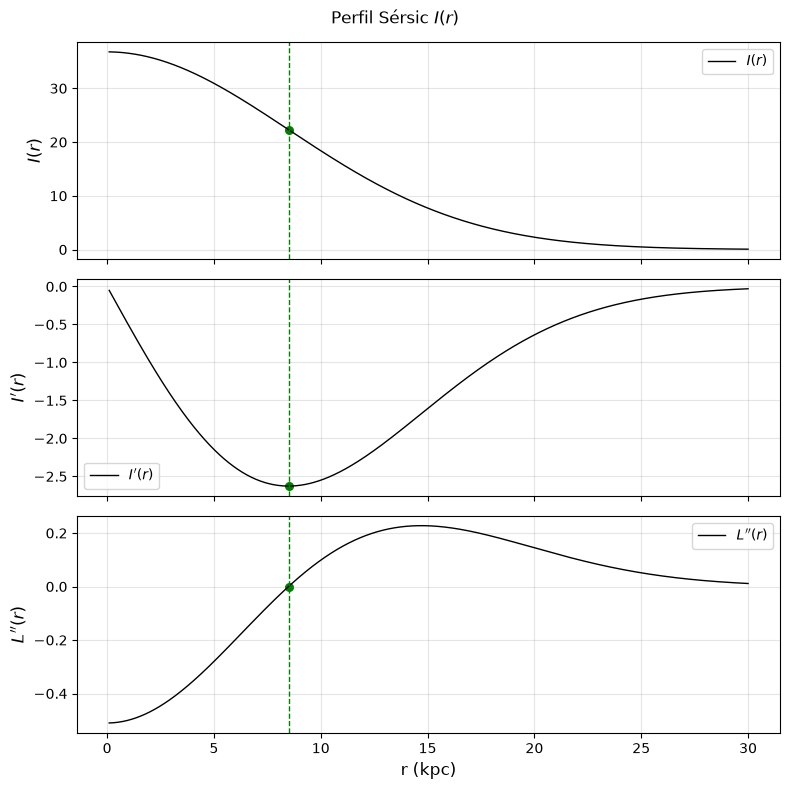

In [53]:
# PARÁMETROS

def bn_func(n):
    if (n > 0.36) and (n < 8):
        A = 4/405
        B = 46/25515
        C = 131/1148175
        D = -2194697/30690717750
        bn = 2 * n - 1/3 + A/n + B/n**2 + C/n**3 + D/n**4
    elif n > 8:
        bn = 2 * n - 1/3
    else:
        raise ValueError('n debe estar en rangos esperados.')
    return bn

n = 0.5
re = 10  # kpc 
I0 = 100 # L_sun / pc^2
r0 = 2   # kpc
bn = bn_func(n)

p = 1/n
k = - bn / re**(p)

E = lambda r: np.exp(k * r**p - 1)
F = lambda r: (p - 1) * r**(p - 2) + k * p * r**(2*p - 2)
G = lambda r: (p - 1) * (p - 2) * r**(p - 3) + (2*p - 2) * k * p * r**(2*p - 3)

def sersic(r):
    return I0 * E(r)

def sersic_dot(r):
    return I0 * k * p * r**(p - 1) * E(r)

def sersic_2dot(r):
    return I0 * k * p * F(r) * E(r)

def sersic_3dot(r):
    return I0 * k * p * ( G(r) + k * p * r**(p - 1) * F(r))

# NEWTON

def optimization_newton(x_start, func, func_dot, func_2dot, tol=1e-10, max_iter=1000):

    x_curr = x_start

    for i in range(1, max_iter + 1):
        x_next = x_curr - func_dot(x_curr) / func_2dot(x_curr)
        if x_next <= 0: 
            x_next = x_curr/2
        if abs((x_next - x_curr)/x_next) < tol:
            return x_next, i

        x_curr = x_next
    print('Newton no convergió.')
    return None, None


# SOLUCIÓN NUMÉRICA

r_min, _ = optimization_newton(r0, sersic_dot, sersic_2dot, sersic_3dot)

# SOLUCIÓN EXACTA

r_min_exac = re * ((1 - n)/bn)**n
if r_min is not None:
    eps = 100 * abs((r_min - r_min_exac)/r_min_exac)
    print(f'La raíz encontrada r* = {r_min:.10f} kpc para n = {n} cuenta con un error relativo porcentual de {eps:.4e}% respecto al valor exacto de {r_min_exac:.10f} kpc.')

# GRÁFICAS

f = [(sersic, r"$I(r)$"), (sersic_dot, r"$I'(r)$"), (sersic_2dot, r"$L''(r)$")]
x = np.linspace(0.1, 30, 1000)

fig, axes = plt.subplots(3, 1, figsize=(8, 8), sharex=True)

for ax, (func, label) in zip(axes, f):
    ax.plot(x, func(x), lw=1, ls='-', color='k', label=label)
    ax.grid(alpha=0.2, color='gray')
    ax.set_ylabel(label, fontsize=12)
    ax.legend()

    if r_min is not None:
        ax.scatter(r_min, func(r_min), s=30, color='green', label=r'$r_{min}$')
        ax.axvline(x = r_min, lw=1, ls='--', color='green')

axes[-1].set_xlabel('r (kpc)', fontsize=12)
fig.suptitle(r'Perfil Sérsic $I(r)$', fontsize=12)
plt.tight_layout()
plt.show()






Para valores del índice de Sérsic $n$ mayores a la unidad, no existe una raíz física que minimice el gradiente $I'(r)$. El valor de $r^{*}$ señala la distancia a la cual la segunda derivada (concavidad de $L(r)$) cambia de signo (punto de inflexión), delimitando distintas regiones de la estructura de la galaxia.